# 03 – Model Evaluation on the Held-Out Test Set
**Deliverable covered:** #7 Evaluation (results table + visualizations), part of #8 (failure cases).

Predictive scores are **context**, not measures of explanation quality.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.utils import *
sns.set_theme(style="whitegrid"); np.random.seed(SEED)

import joblib
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
X_train, X_test, y_train, y_test = load_split()
names = ["E1_LR_baseline","E2_LR_balanced","E3_RF_default","E4_RF_balanced_reg","E5_RF_tuned"]
models = {n: joblib.load(MODELS_DIR/f"{n}.joblib") for n in names}

In [2]:
rows, proba = [], {}
for n,m in models.items():
    p = m.predict_proba(X_test)[:,1]; yhat = (p>=0.5).astype(int); proba[n]=p
    rows.append({"model":n,"accuracy":accuracy_score(y_test,yhat),"precision":precision_score(y_test,yhat),
                 "recall":recall_score(y_test,yhat),"f1":f1_score(y_test,yhat),
                 "roc_auc":roc_auc_score(y_test,p),"pr_auc":average_precision_score(y_test,p)})
res = pd.DataFrame(rows).set_index("model").round(4)
res.to_csv(RESULTS_DIR/"test_metrics.csv")
print("Majority-class baseline accuracy:", round(1-y_test.mean(),4))
res

Majority-class baseline accuracy: 0.7346


,accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,
E1_LR_baseline,0.8055,0.6572,0.5588,0.6040,0.8419,0.6340
E2_LR_balanced,0.7381,0.5043,0.7834,0.6136,0.8414,0.6324
E3_RF_default,0.7828,0.6118,0.4973,0.5487,0.8214,0.6156
E4_RF_balanced_reg,0.7594,0.5322,0.7727,0.6303,0.8408,0.6507
E5_RF_tuned,0.8034,0.6714,0.5080,0.5784,0.8447,0.6592


### Visualization 1 – Confusion matrices

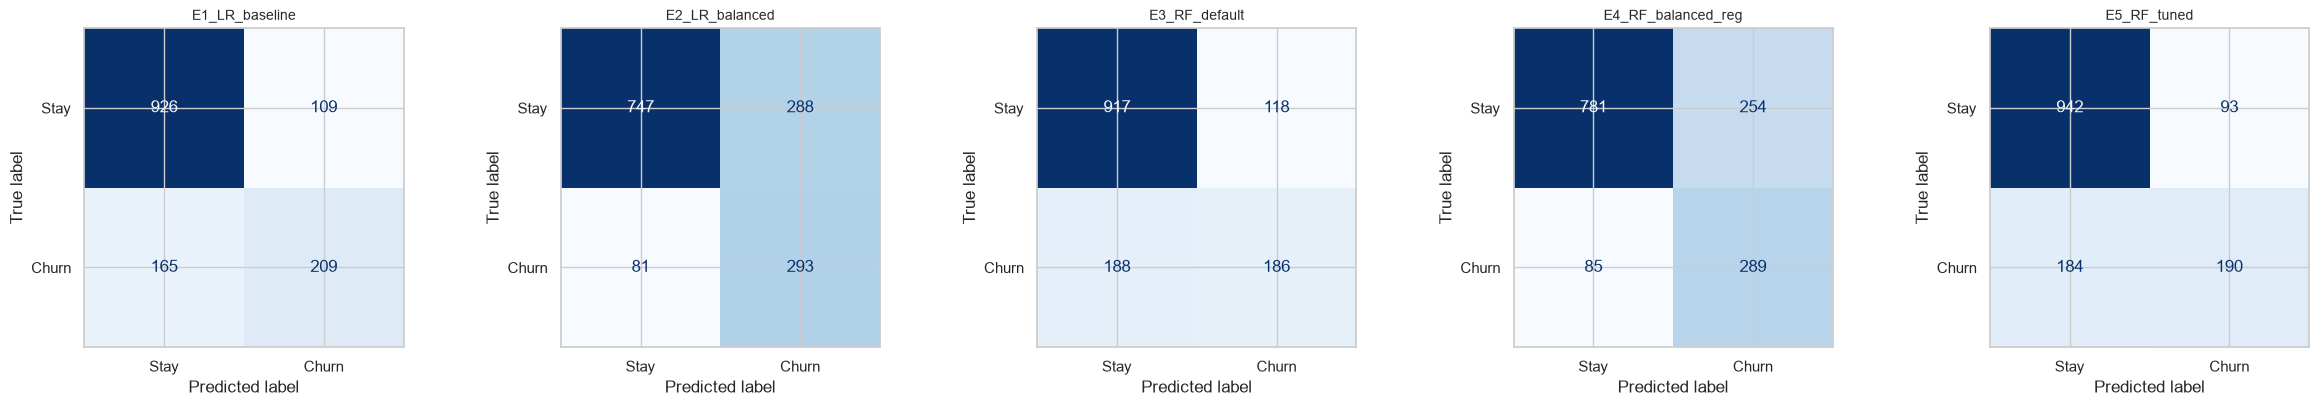

In [3]:
fig, axes = plt.subplots(1,5, figsize=(24,4.2))
for ax,(n,m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba[n]>=0.5).astype(int), display_labels=["Stay","Churn"],
                                            cmap="Blues", colorbar=False, ax=ax); ax.set_title(n, fontsize=10)
plt.tight_layout(); plt.savefig(VIS_DIR/"confusion_matrix.png", dpi=150); plt.show()

### Visualization 2 – ROC and Precision–Recall curves

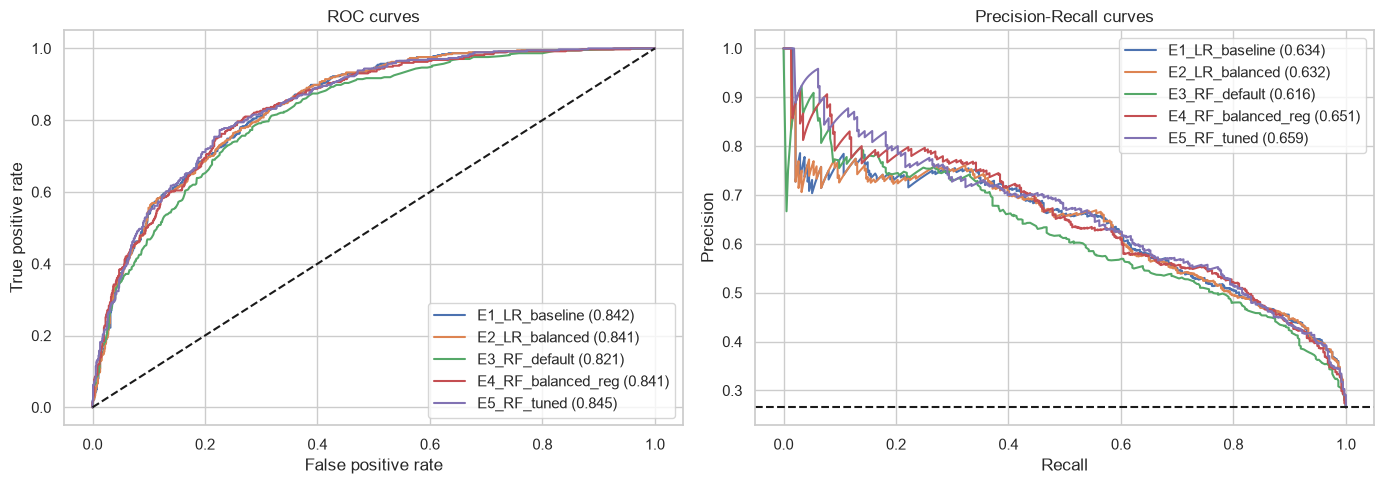

In [4]:
fig, (a1,a2) = plt.subplots(1,2, figsize=(14,5))
for n,p in proba.items():
    fpr,tpr,_ = roc_curve(y_test,p); a1.plot(fpr,tpr,label=f"{n} ({res.loc[n,'roc_auc']:.3f})")
    pr,rc,_ = precision_recall_curve(y_test,p); a2.plot(rc,pr,label=f"{n} ({res.loc[n,'pr_auc']:.3f})")
a1.plot([0,1],[0,1],"k--"); a1.set(title="ROC curves",xlabel="False positive rate",ylabel="True positive rate"); a1.legend()
a2.axhline(y_test.mean(),c="k",ls="--"); a2.set(title="Precision-Recall curves",xlabel="Recall",ylabel="Precision"); a2.legend()
plt.tight_layout(); plt.savefig(VIS_DIR/"roc_pr_curves.png", dpi=150); plt.show()

### Visualization 3 – Metric comparison

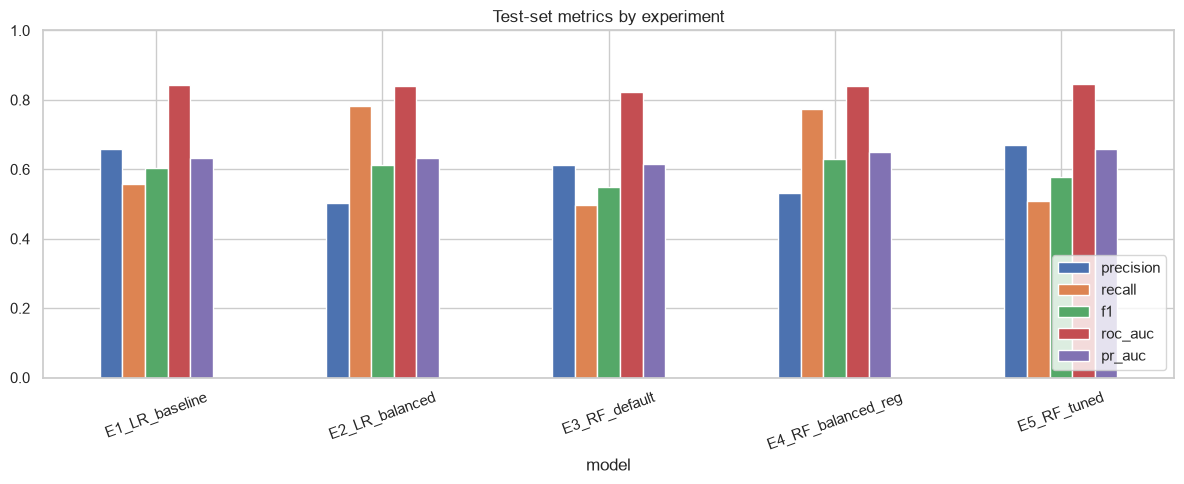

In [5]:
res[["precision","recall","f1","roc_auc","pr_auc"]].plot(kind="bar", figsize=(12,5), rot=20)
plt.title("Test-set metrics by experiment"); plt.ylim(0,1); plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(VIS_DIR/"metric_comparison.png", dpi=150); plt.show()

### Visualization 4 – Decision-threshold trade-off (best model by ROC-AUC)

Best by ROC-AUC: E5_RF_tuned


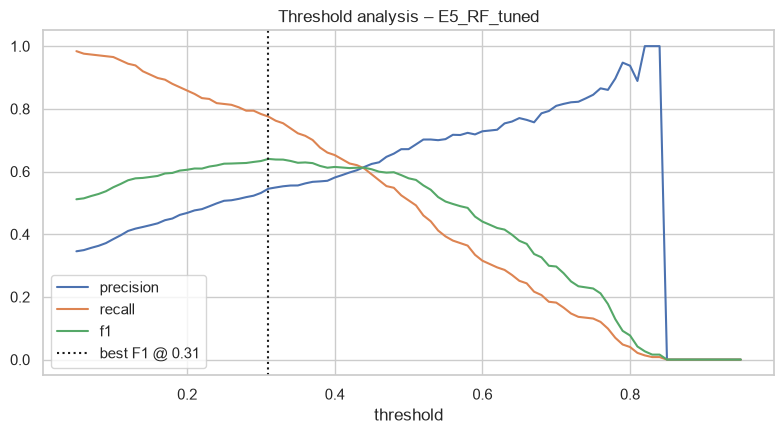

In [6]:
best = res["roc_auc"].idxmax(); print("Best by ROC-AUC:", best)
ths = np.linspace(0.05,0.95,91); p = proba[best]
m = pd.DataFrame({"threshold":ths,
    "precision":[precision_score(y_test,p>=t,zero_division=0) for t in ths],
    "recall":[recall_score(y_test,p>=t) for t in ths],
    "f1":[f1_score(y_test,p>=t) for t in ths]}).set_index("threshold")
m.plot(figsize=(8,4.5)); plt.axvline(m.f1.idxmax(), c="k", ls=":", label=f"best F1 @ {m.f1.idxmax():.2f}")
plt.title(f"Threshold analysis – {best}"); plt.legend(); plt.tight_layout()
plt.savefig(VIS_DIR/"threshold_analysis.png", dpi=150); plt.show()

## Failure-case analysis
Which churners does the model miss (false negatives) and which loyal customers does it flag (false positives)?

In [7]:
p = proba["E5_RF_tuned"]; yhat=(p>=0.5).astype(int)
te = X_test.copy(); te["y"]=y_test.values; te["p_churn"]=p
fn = te[(te.y==1)&(yhat==0)]; tp = te[(te.y==1)&(yhat==1)]; fp = te[(te.y==0)&(yhat==1)]
print(f"False negatives: {len(fn)} | True positives: {len(tp)} | False positives: {len(fp)}")
cmp = pd.DataFrame({"FN_missed_churners":fn[["tenure","MonthlyCharges"]].mean(), "TP_caught_churners":tp[["tenure","MonthlyCharges"]].mean(),
                    "FP_false_alarms":fp[["tenure","MonthlyCharges"]].mean()})
display(cmp.round(1))
display(pd.DataFrame({"FN":fn.Contract.value_counts(normalize=True),"TP":tp.Contract.value_counts(normalize=True),
                      "FP":fp.Contract.value_counts(normalize=True)}).round(3))

False negatives: 184 | True positives: 190 | False positives: 93


,FN_missed_churners,TP_caught_churners,FP_false_alarms
tenure,26.5,6.7,9.3
MonthlyCharges,68.4,77.0,77.7


,FN,TP,FP
Contract,,,
Month-to-month,0.755,1.0,1.0
One year,0.196,NaN,NaN
Two year,0.049,NaN,NaN


**To discuss in the report:** missed churners tend to look like loyal customers (longer tenure, longer contracts), so the model has little signal for them; false alarms look like typical churners who stayed. Quantify using the tables above.